# Llama：特異値10等分削除のPPLとDEの比較

保存済みLlama結果だけを読むCPU用ノートブック。モデル・SVD・DE・PPLの再計算は行いません。Gemmaは読み込みません。

横：UP / DOWN / GATE / Q / K / V / O、上段：DEなし、下段：DEあり。各パネルに10群の棒を表示します。

## 実行方法・比較条件
「すべて実行」で検証、集計、PNG/PDF/CSV保存まで行います。必要ライブラリはnumpy、pandas、matplotlib。ローカルPythonで実行可能（Colabを使う場合もGPU不要）。

- 群1＝最小10%、群10＝最大10%。各モジュールの全28ブロックで同じ順位帯を同時に削除。
- 毎回元モデルに戻して比較。DEありでは変換後の成分を除き、元座標へ戻す。
- 主図はPPLそのもの。論文Fig. 5と同じ指標の図は **ΔPPL＝削除後PPL−無変更baseline**。
- 最大群による大きな悪化を隠さず表示。対数PPL図も補助として出力。
- 上下のDE条件は同じ縦軸範囲。既定ではモジュールごとに範囲を設定し、異なるモジュール間の棒の高さは直接比較しない。
- 原論文と同じ図の配置を参考にするが、モデル等は完全再現ではない。参照：[Staats et al., 2025, Fig. 5](https://arxiv.org/html/2410.17770v3#S5.F5)。


In [1]:
from pathlib import Path
import json, hashlib, unicodedata, os, tempfile
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir())/'rmt11-analysis-mpl'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# 別の場所に保存している場合だけ設定する。
DATA_ROOT_OVERRIDE = None
VERIFY_CHECKSUMS = True
SHARE_Y_ACROSS_MODULES = False
GROUPS = ['UP','DOWN','GATE','Q','K','V','O']
if DATA_ROOT_OVERRIDE:
    DATA_ROOT = Path(DATA_ROOT_OVERRIDE)
elif Path('/content').exists():
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_ROOT = Path('/content/drive/MyDrive/TUS/hashiguchi/data')
else:
    base = Path.home()/'Library/CloudStorage/GoogleDrive-ryoya.zushi1210@gmail.com'
    roots = [p/'TUS/hashiguchi/data' for p in base.iterdir()
             if unicodedata.normalize('NFC',p.name)=='マイドライブ']
    if len(roots)!=1: raise RuntimeError('DATA_ROOT_OVERRIDEを指定してください')
    DATA_ROOT = roots[0]
SOURCE = DATA_ROOT/'ibis2026_de_lra/decile-module-de-v1'
OUTPUT = DATA_ROOT/'ibis2026_de_lra/decile-module-llama-analysis-v1'
OUTPUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'font.size':11, 'axes.spines.top':False, 'axes.spines.right':False})
print('入力:', SOURCE, '\n出力:', OUTPUT)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
入力: /content/drive/MyDrive/TUS/hashiguchi/data/ibis2026_de_lra/decile-module-de-v1 
出力: /content/drive/MyDrive/TUS/hashiguchi/data/ibis2026_de_lra/decile-module-llama-analysis-v1


## 保存結果の検証
140条件とbaselineの存在、設定ハッシュ、保存損失・行列計画のチェックサム、PPLの再集計、DE前後の削除個数を確認します。
不足がある場合はここで停止し、未実行を0として描画しません。計算済み結果は変更しません。


In [2]:
def sha(p): return hashlib.sha256(p.read_bytes()).hexdigest()
manifest = json.loads((SOURCE/'manifest.json').read_text())
config_hash = manifest['config_hash']
audit = []
def read_result(path):
    obj = json.loads((path/'summary.json').read_text())
    assert obj['model']=='llama' and obj['config_hash']==config_hash, str(path)
    f = path/'losses.npz'
    if VERIFY_CHECKSUMS: assert sha(f)==obj['loss_hash'], str(f)
    with np.load(f, allow_pickle=False) as z:
        loss, count = z['loss'], z['count']
    assert loss.shape==count.shape==(282,)
    assert np.isfinite(loss).all() and (count==1023).all()
    ppl = float(np.exp(loss.sum()/count.sum()))
    assert not obj['ppl_overflow'] and np.isfinite(ppl)
    assert np.isclose(ppl,obj['ppl'],rtol=1e-10), str(path)
    audit.append({'path':str(path.relative_to(SOURCE)), 'summary_sha256':sha(path/'summary.json'),
                  'loss_sha256':obj['loss_hash']})
    return obj
base = read_result(SOURCE/'llama/baseline')
baseline = base['ppl']
rows=[]; missing=[]
for group in GROUPS:
    for de in [False,True]:
        for decile in range(1,11):
            path=SOURCE/'llama/groups'/group/f'{int(de)}_decile{decile:02d}'
            if not (path/'summary.json').exists():
                missing.append((group,de,decile)); continue
            obj=read_result(path)
            assert (obj['group'],obj['de'],obj['decile'])==(group,de,decile)
            assert obj['matrix_count']==28 and np.isclose(obj['baseline_ppl'],baseline)
            if VERIFY_CHECKSUMS: assert sha(path/'matrices.json')==obj['matrix_plan_hash']
            records=json.loads((path/'matrices.json').read_text())['records']
            assert len(records)==28 and len({r['name'] for r in records})==28
            assert sum(r['removed'] for r in records)==obj['sum_removed']
            assert sum(r['retained_rank'] for r in records)==obj['sum_rank']
            rows.append(obj)
if missing: raise RuntimeError(f'未保存条件 {len(missing)}件: {missing}')
df=pd.DataFrame(rows)
assert len(df)==140 and not df.duplicated(['group','de','decile']).any()
for _,a in df.groupby(['group','decile']):
    assert a['sum_removed'].nunique()==1 and a['sum_rank'].nunique()==1
    assert set(a.de)=={False,True}
df['delta_ppl']=df.ppl-baseline
df['ppl_ratio_to_baseline']=df.ppl/baseline
df.to_csv(OUTPUT/'llama_decile_results.csv',index=False)
(OUTPUT/'input_audit.json').write_text(json.dumps({'source':str(SOURCE),'config_hash':config_hash,
    'checksums_verified':VERIFY_CHECKSUMS,'files':audit},indent=2))
print(f'PASS: 140条件＋baseline。baseline PPL = {baseline:.6f}')
display(df.groupby(['group','de']).size().unstack().reindex(GROUPS).rename(columns={False:'DE off',True:'DE on'}))


PASS: 140条件＋baseline。baseline PPL = 8.753665


de,DE off,DE on
group,,
UP,10,10
DOWN,10,10
GATE,10,10
Q,10,10
K,10,10
V,10,10
O,10,10


## 可視化：モジュールを横、DEを上下に配置
灰色＝DEなし、青＝DEあり。破線は無変更baseline。

線形PPL図は0起点。対数PPL図は比率を見る補助図で、棒の長さはPPL差を表しません。
ΔPPL図はStaatsらと同じ評価量で、0を下回る場合は改善です。図中の順位帯は個数による分割であり、MPの外れ値領域ではありません。


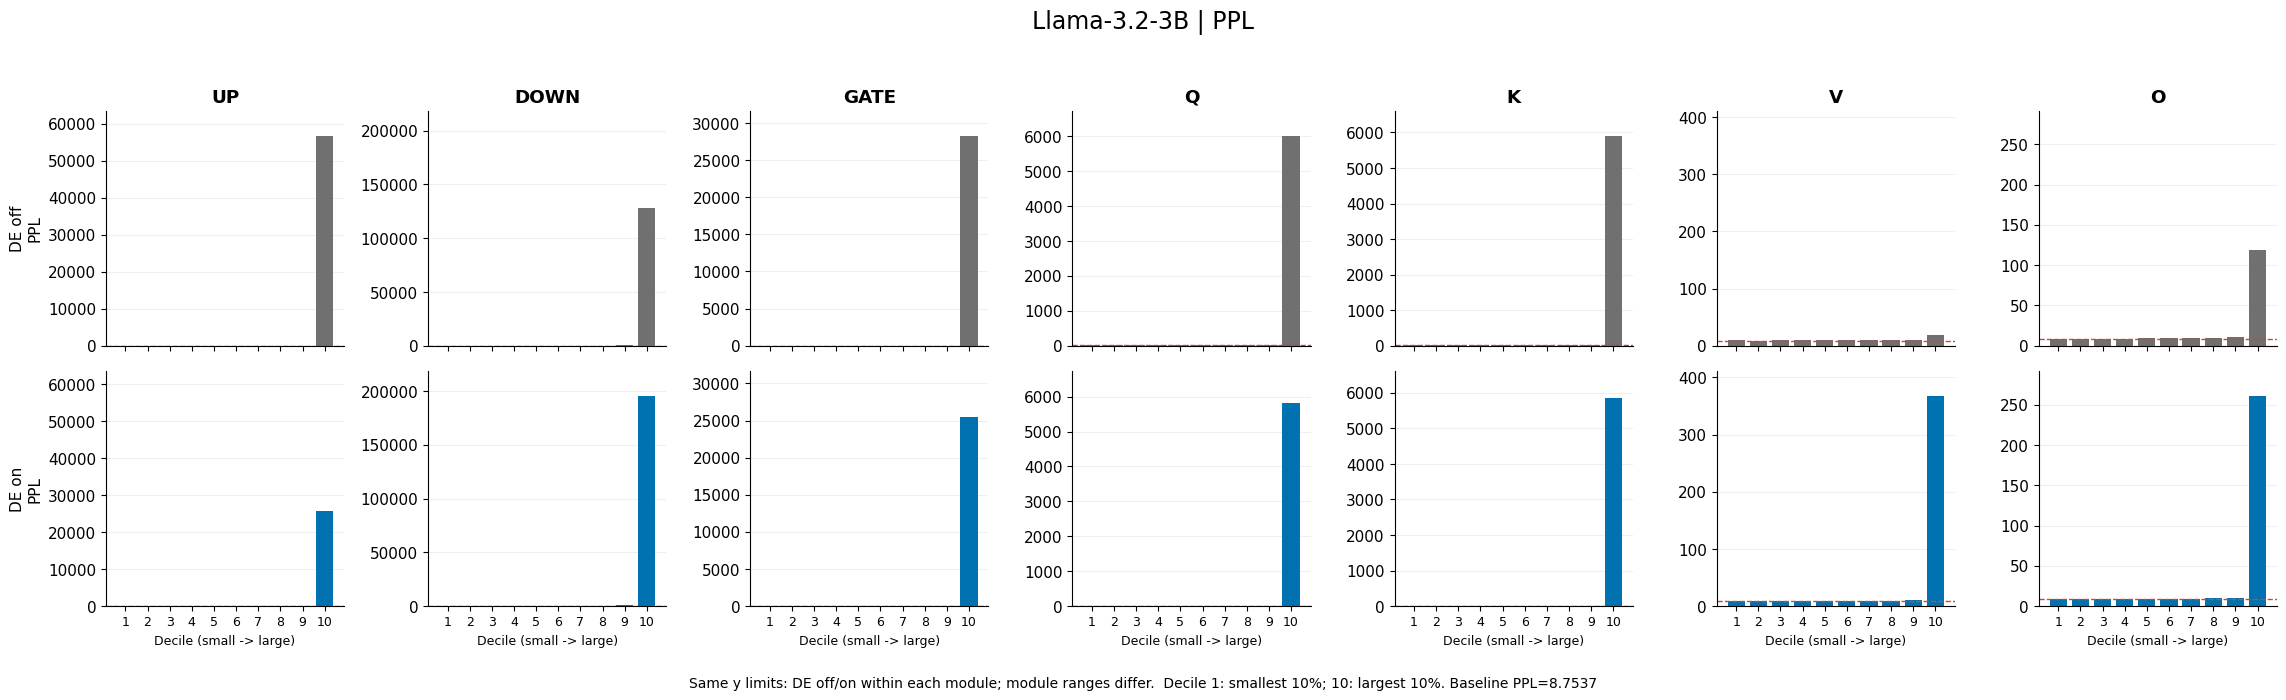

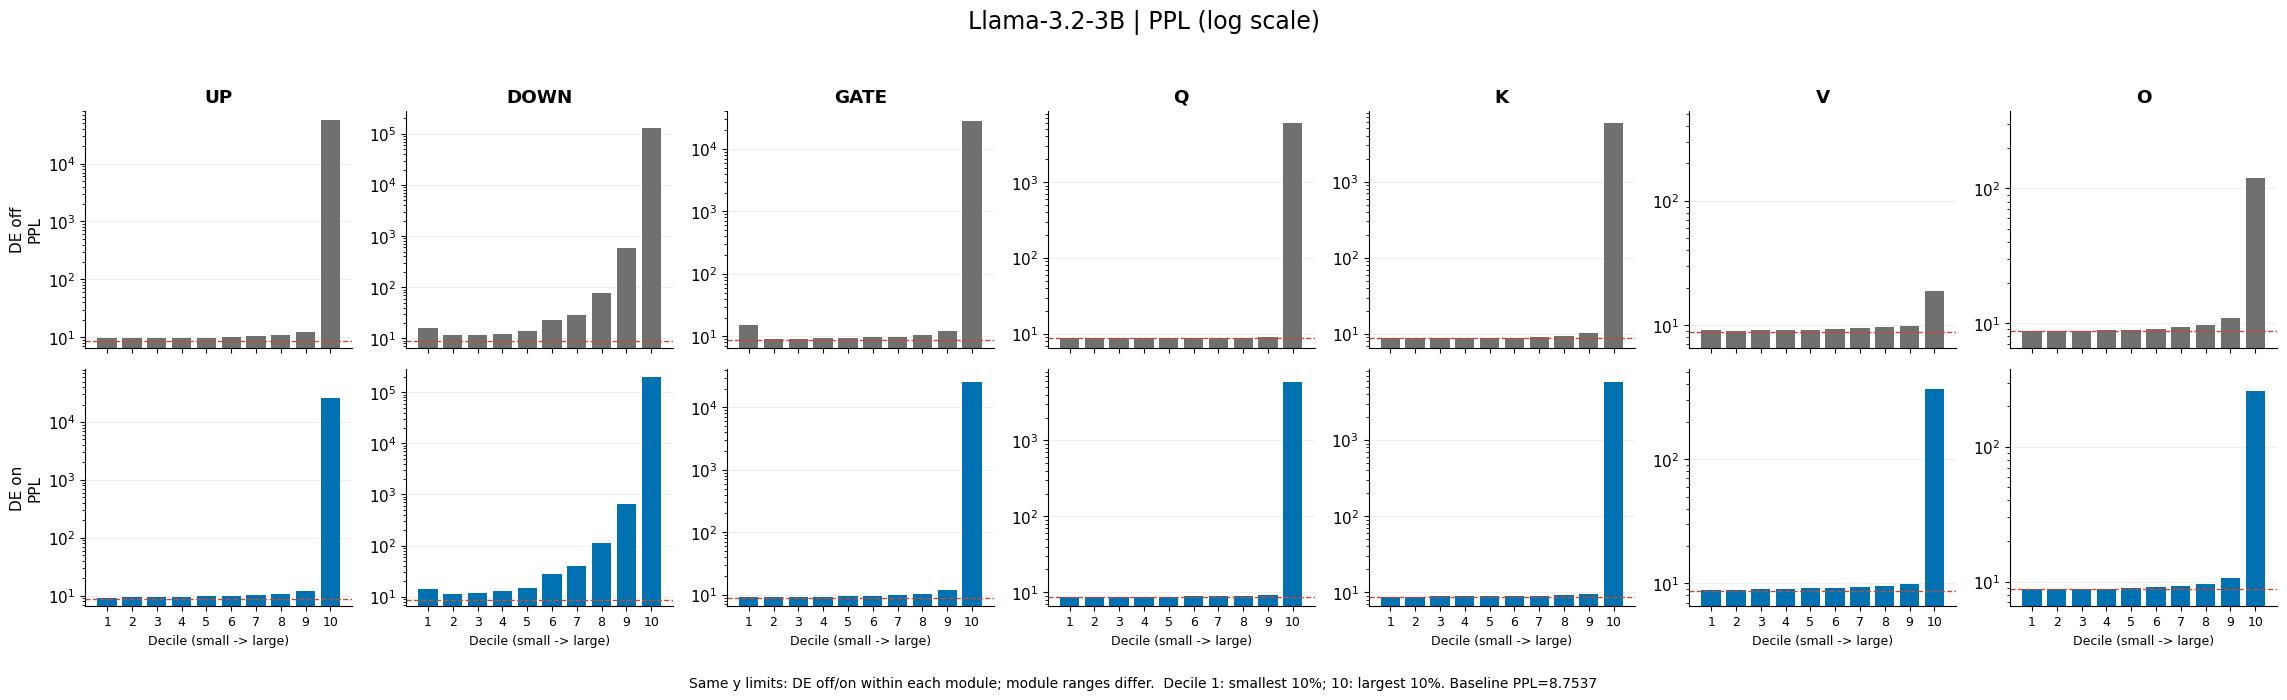

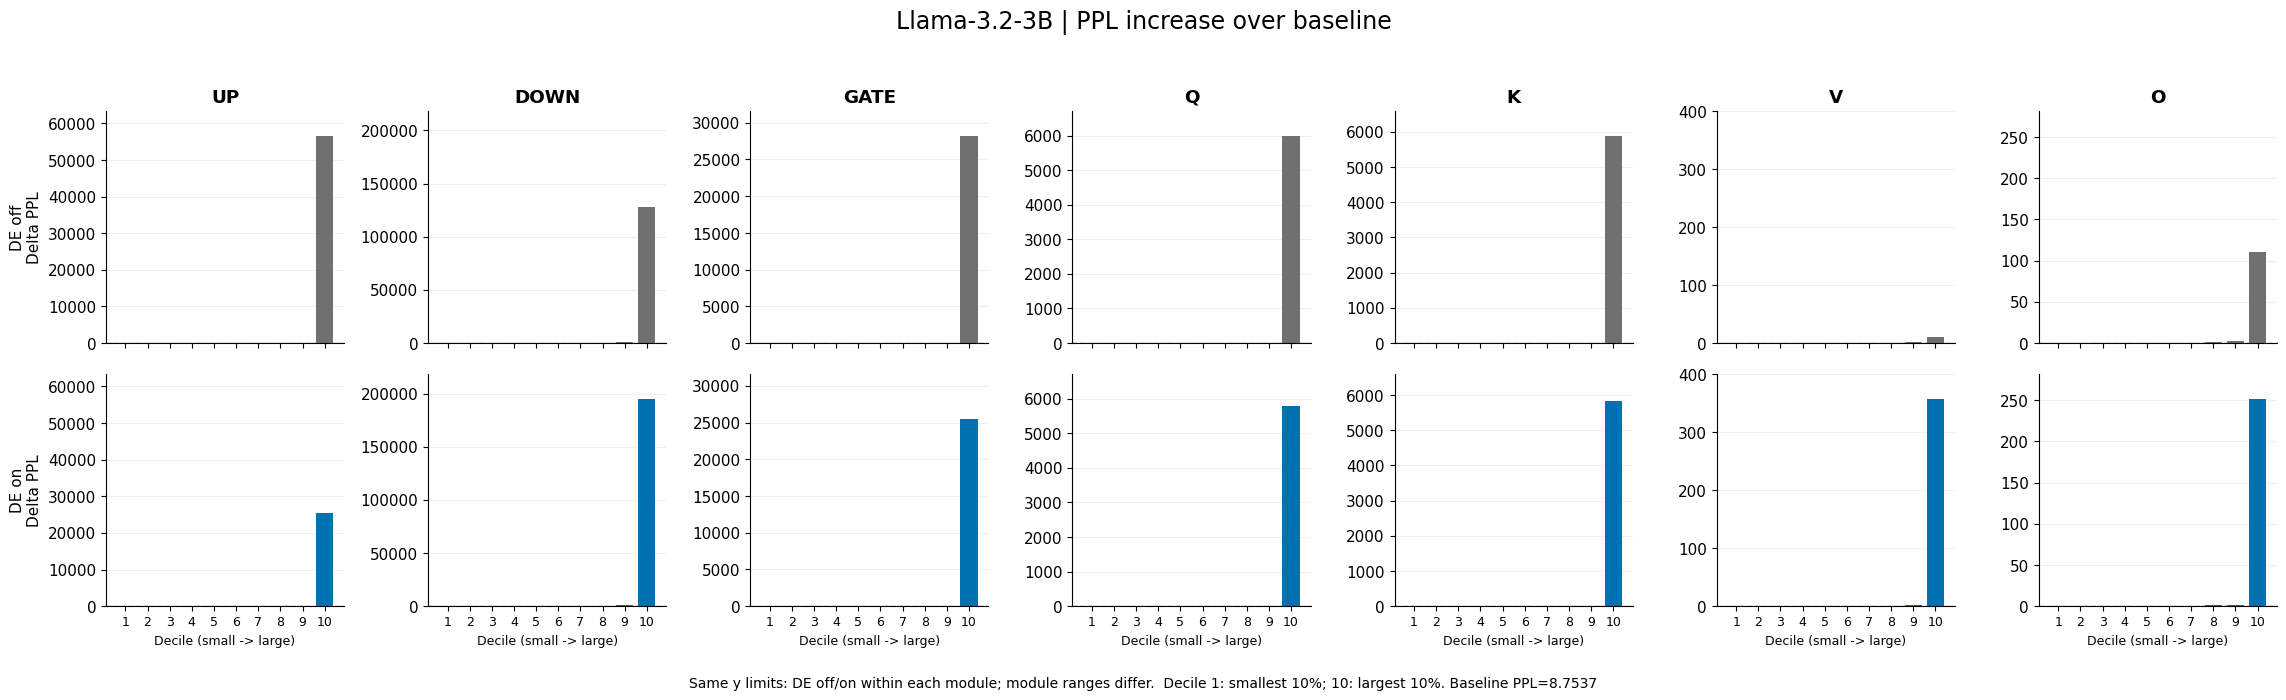

In [3]:
def plot_grid(metric='ppl', log=False):
    fig, axes = plt.subplots(2,7,figsize=(23,7),sharex=True)
    for col,group in enumerate(GROUPS):
        panel=df[df.group==group]
        scale_data=df if SHARE_Y_ACROSS_MODULES else panel
        y=scale_data[metric].to_numpy()
        if log:
            assert (y>0).all()
            limits=(min(y.min(),baseline)*.75,max(y.max(),baseline)*1.45)
        else:
            low=min(0,float(y.min())); high=max(float(y.max()),baseline if metric=='ppl' else 0)
            span=max(high-low,1e-6);limits=(low-.06*span if low<0 else 0,high+.12*span)
        for row,de in enumerate([False,True]):
            ax=axes[row,col];a=panel[panel.de==de].sort_values('decile')
            ax.bar(a.decile,a[metric],color='#707070' if not de else '#0072B2',width=.78)
            if log: ax.set_yscale('log')
            ax.set_ylim(*limits);ax.set_xticks(range(1,11));ax.tick_params(axis='x',labelsize=9)
            ax.axhline(baseline if metric=='ppl' else 0,color='#C34A36',ls='--',lw=1)
            ax.grid(axis='y',alpha=.2);ax.set_axisbelow(True)
            if row==0:ax.set_title(group,fontweight='bold')
            if col==0:ax.set_ylabel(('DE off' if not de else 'DE on')+'\n'+('PPL' if metric=='ppl' else 'Delta PPL'))
            if row==1:ax.set_xlabel('Decile (small -> large)',fontsize=9)
    kind='PPL (log scale)' if log else ('PPL' if metric=='ppl' else 'PPL increase over baseline')
    fig.suptitle('Llama-3.2-3B | '+kind,fontsize=17)
    scope='all modules' if SHARE_Y_ACROSS_MODULES else 'DE off/on within each module; module ranges differ'
    fig.text(.5,.012,f'Same y limits: {scope}.  Decile 1: smallest 10%; 10: largest 10%. Baseline PPL={baseline:.4f}',ha='center',fontsize=10)
    fig.tight_layout(rect=[0,.045,1,.95])
    name='module_deciles_'+metric+('_log' if log else '_linear')
    fig.savefig(OUTPUT/(name+'.png'),dpi=180,bbox_inches='tight')
    fig.savefig(OUTPUT/(name+'.pdf'),bbox_inches='tight')
    plt.show();plt.close(fig)
plot_grid('ppl')
plot_grid('ppl',log=True)
plot_grid('delta_ppl')


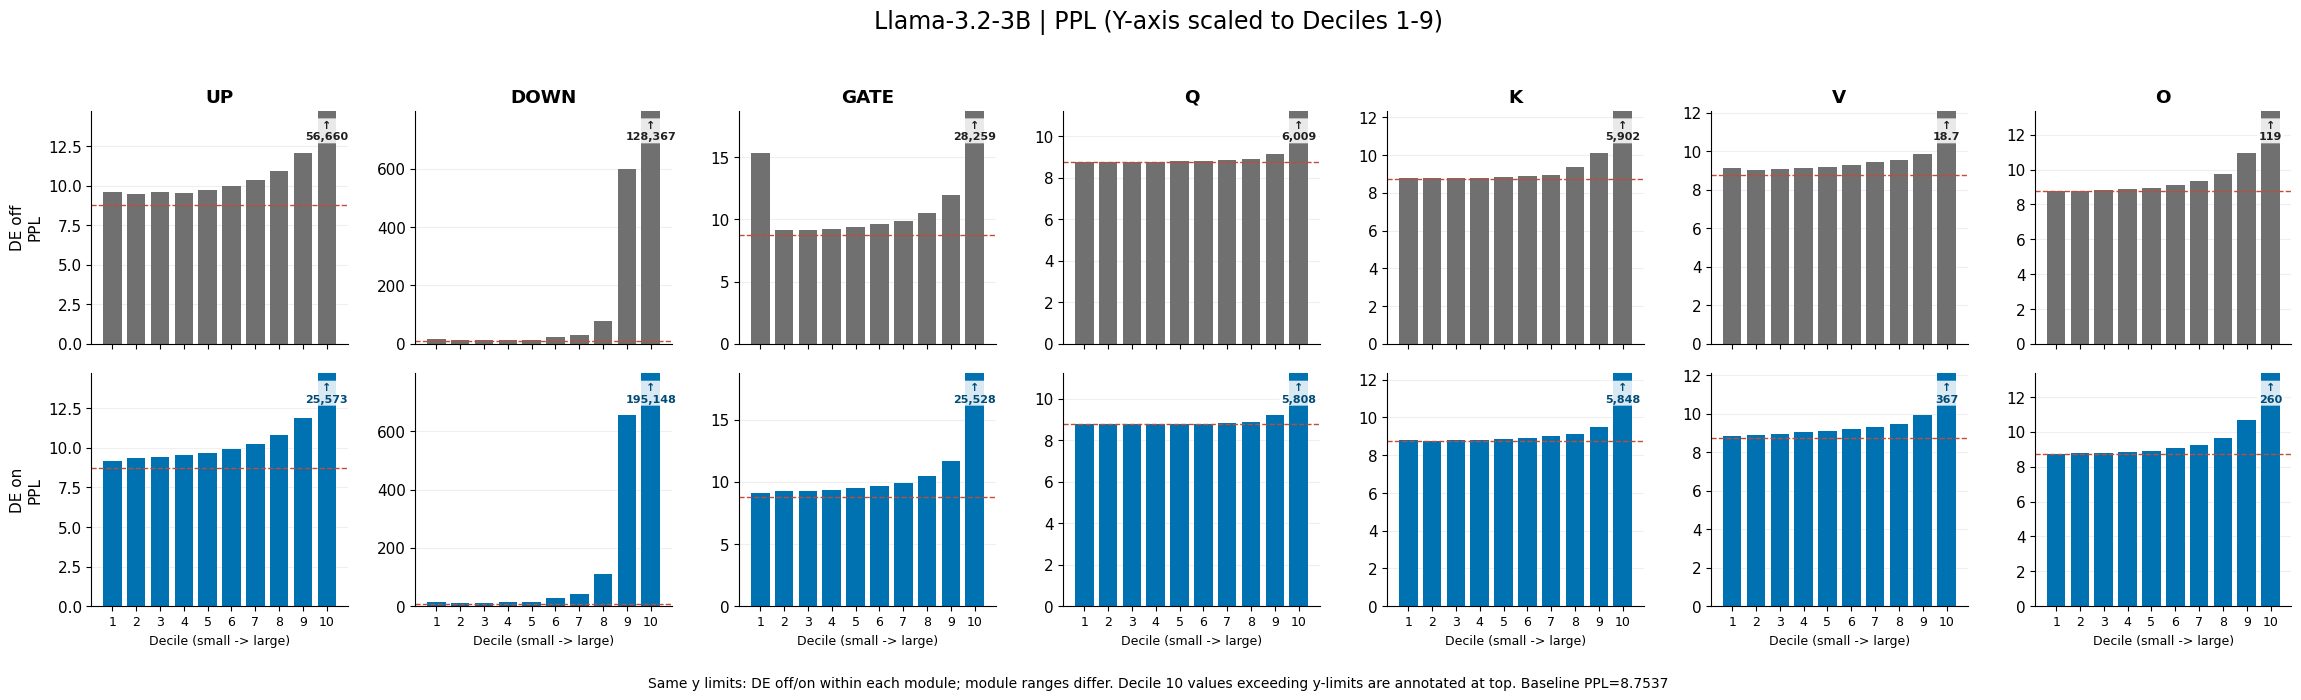

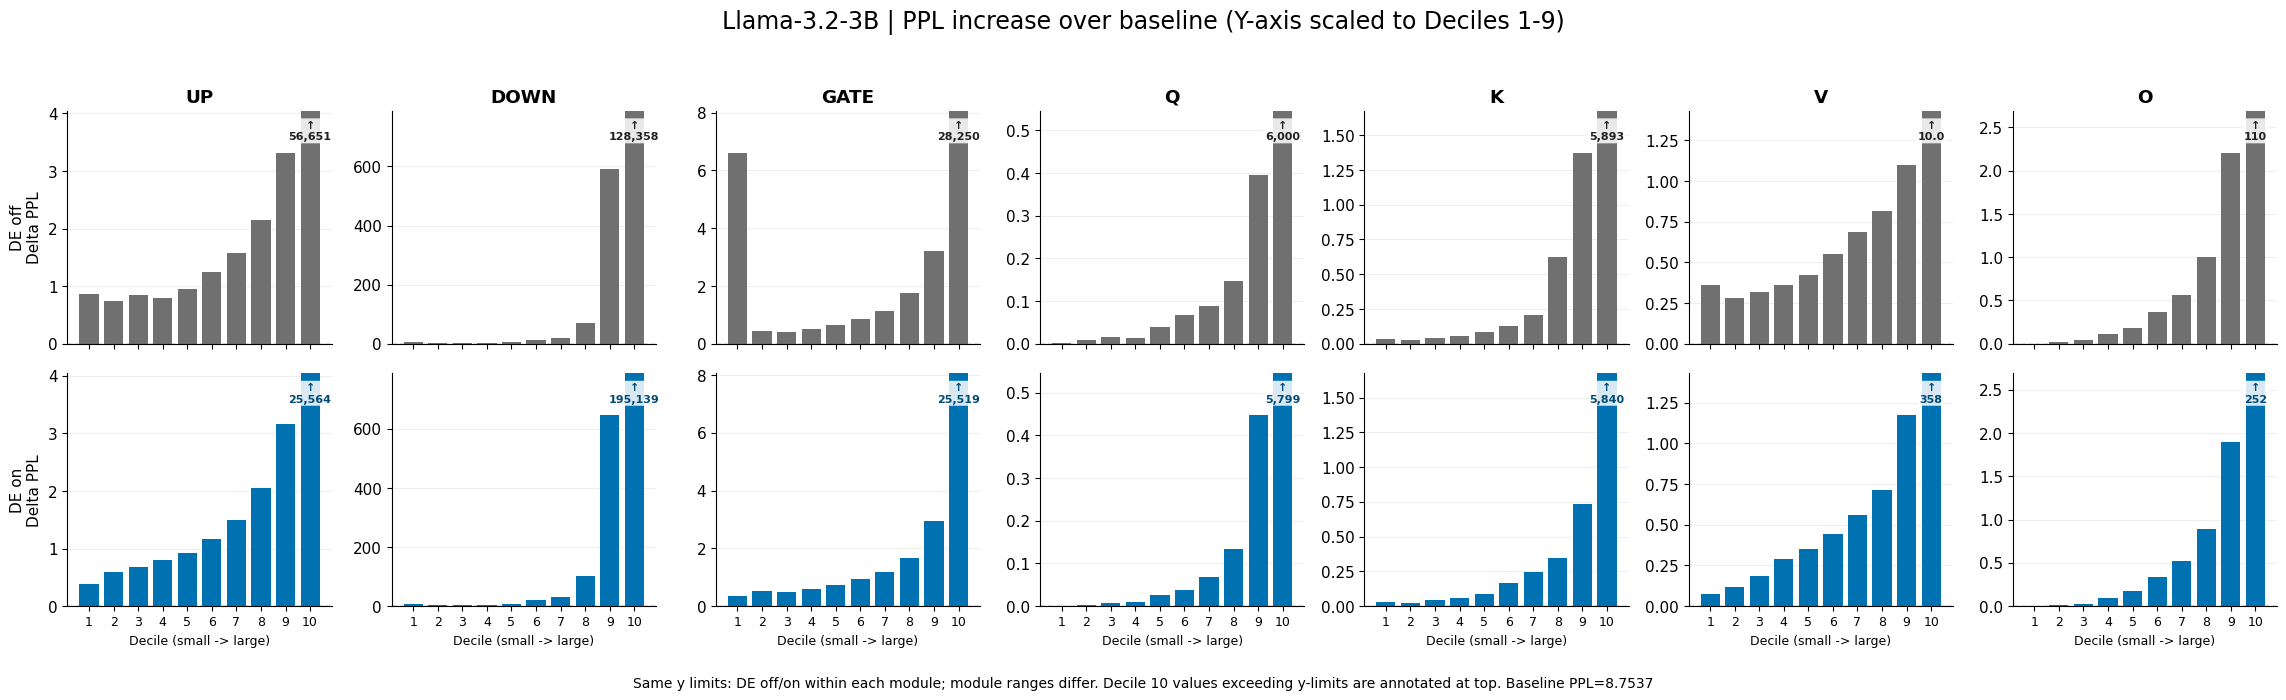

In [5]:
def plot_grid_clipped(metric='ppl', clip_decile=10):
    fig, axes = plt.subplots(2, 7, figsize=(23, 7), sharex=True)
    for col, group in enumerate(GROUPS):
        panel = df[df.group == group]
        scale_data = df if SHARE_Y_ACROSS_MODULES else panel
        
        # 外れ値（Decile 10）を除いたデータでY軸の範囲を計算する
        scale_sub = scale_data[scale_data.decile != clip_decile]
        y = scale_sub[metric].to_numpy()
        
        low = min(0, float(y.min()))
        high = max(float(y.max()), baseline if metric == 'ppl' else 0)
        span = max(high - low, 1e-6)
        # テキスト表示用の余白を上部に少し広め（+22%）に確保
        limits = (low - .06 * span if low < 0 else 0, high + .22 * span)
        
        for row, de in enumerate([False, True]):
            ax = axes[row, col]
            a = panel[panel.de == de].sort_values('decile')
            bars = ax.bar(a.decile, a[metric], color='#707070' if not de else '#0072B2', width=.78)
            
            ax.set_ylim(*limits)
            ax.set_xticks(range(1, 11))
            ax.tick_params(axis='x', labelsize=9)
            ax.axhline(baseline if metric == 'ppl' else 0, color='#C34A36', ls='--', lw=1)
            ax.grid(axis='y', alpha=.2)
            ax.set_axisbelow(True)
            
            # Y軸の上限を超えたバー（Decile 10など）の上部に実際の数値を表示
            for d_val, val in zip(a.decile, a[metric]):
                if val > limits[1]:
                    # 数値が大きい場合はカンマ区切りや指数表記で見やすくする
                    label_str = f'{val:,.0f}' if val >= 100 else f'{val:.1f}'
                    ax.text(d_val, limits[1] * 0.96, f'↑\n{label_str}', 
                            ha='center', va='top', fontsize=8, fontweight='bold',
                            color='#202020' if not de else '#004B76',
                            bbox=dict(boxstyle='round,pad=0.15', facecolor='white', alpha=0.85, edgecolor='none'))

            if row == 0: ax.set_title(group, fontweight='bold')
            if col == 0: ax.set_ylabel(('DE off' if not de else 'DE on') + '\n' + ('PPL' if metric == 'ppl' else 'Delta PPL'))
            if row == 1: ax.set_xlabel('Decile (small -> large)', fontsize=9)
            
    kind = 'PPL' if metric == 'ppl' else 'PPL increase over baseline'
    fig.suptitle(f'Llama-3.2-3B | {kind} (Y-axis scaled to Deciles 1-9)', fontsize=17)
    scope = 'all modules' if SHARE_Y_ACROSS_MODULES else 'DE off/on within each module; module ranges differ'
    fig.text(.5, .012, f'Same y limits: {scope}. Decile 10 values exceeding y-limits are annotated at top. Baseline PPL={baseline:.4f}', ha='center', fontsize=10)
    fig.tight_layout(rect=[0, .045, 1, .95])
    
    name = f'module_deciles_{metric}_clipped'
    fig.savefig(OUTPUT / (name + '.png'), dpi=180, bbox_inches='tight')
    fig.savefig(OUTPUT / (name + '.pdf'), bbox_inches='tight')
    plt.show()
    plt.close(fig)

plot_grid_clipped('ppl')
plot_grid_clipped('delta_ppl')


## DE前後の対応比較と最小群の位置づけ
PPL改善率＝100×(1−DEありPPL／DEなしPPL)。正ならDE有利。
「重要度順位」は削除後PPLが大きい順（1位が最も影響が大きい）。同率は最小順位を使用します。

最小群と中央の群2〜9の比較は、同一DE条件内で行います。相対的な削除感度の観測であり、情報が上側へ移動したことの直接証明ではありません。群によって削除エネルギーは異なり、DE前後で同じ特異方向を削除しているわけでもありません。


In [4]:
paired=df.pivot(index=['group','decile'],columns='de',values='ppl').rename(columns={False:'ppl_off',True:'ppl_de'})
paired['gain_pct']=100*(1-paired.ppl_de/paired.ppl_off)
paired['ppl_difference_de_minus_off']=paired.ppl_de-paired.ppl_off
paired.reset_index().to_csv(OUTPUT/'paired_deciles.csv',index=False)
summary=[]
for group in GROUPS:
    row={'module':group}
    for de in [False,True]:
        a=df[(df.group==group)&(df.de==de)].set_index('decile')
        tag='DE' if de else 'off'
        row['smallest_ppl_'+tag]=a.loc[1,'ppl']
        row['smallest_delta_'+tag]=a.loc[1,'delta_ppl']
        row['smallest_importance_rank_'+tag]=int(a.ppl.rank(ascending=False,method='min').loc[1])
        row['central_groups_less_affected_'+tag]=int((a.loc[2:9,'ppl']<a.loc[1,'ppl']).sum())
    row['smallest_gain_pct']=paired.loc[(group,1),'gain_pct']
    summary.append(row)
summary=pd.DataFrame(summary)
summary.to_csv(OUTPUT/'smallest_decile_summary.csv',index=False)
display(summary.round(4))
display(paired['gain_pct'].unstack('decile').reindex(GROUPS).round(2))
lines=['# Llama：最小特異値群の削除感度', f'無変更baseline PPL: {baseline:.6f}',
       '削除感度順位は各モジュール・各DE条件でPPLが大きい順。因果的な情報移動を意味しない。']
for r in summary.to_dict('records'):
    lines.append(f"- {r['module']}: 最小群の削除後PPL {r['smallest_ppl_off']:.4f} → {r['smallest_ppl_DE']:.4f}; "
                 f"影響順位 {r['smallest_importance_rank_off']} → {r['smallest_importance_rank_DE']}; "
                 f"DEによるPPL改善率 {r['smallest_gain_pct']:+.2f}%")
text='\n\n'.join(lines)
(OUTPUT/'summary.md').write_text(text)
display(Markdown(text))
print('保存先:',OUTPUT)


,module,smallest_ppl_off,smallest_delta_off,smallest_importance_rank_off,central_groups_less_affected_off,smallest_ppl_DE,smallest_delta_DE,smallest_importance_rank_DE,central_groups_less_affected_DE,smallest_gain_pct
0,UP,9.6111,0.8574,7,3,9.1388,0.3851,10,0,4.9139
1,DOWN,16.0781,7.3245,6,4,14.4499,5.6962,7,3,10.1272
2,GATE,15.3666,6.6130,2,8,9.1148,0.3611,10,0,40.6845
3,Q,8.7563,0.0026,10,0,8.7545,0.0009,10,0,0.0197
4,K,8.7845,0.0309,9,1,8.7842,0.0306,9,1,0.0035
5,V,9.1141,0.3605,8,2,8.8308,0.0772,10,0,3.1081
6,O,8.7558,0.0021,10,0,8.7540,0.0004,10,0,0.0199


decile,1,2,3,4,5,6,7,8,9,10
group,,,,,,,,,,
UP,4.91,1.65,1.79,-0.09,0.25,0.74,0.77,0.88,1.31,54.87
DOWN,10.13,0.44,-1.22,-4.94,-4.61,-24.25,-40.23,-42.87,-9.44,-52.02
GATE,40.68,-1.02,-0.94,-0.99,-0.93,-0.81,-0.38,0.80,2.42,9.66
Q,0.02,0.08,0.10,0.04,0.14,0.32,0.23,0.14,-0.56,3.34
K,0.00,0.01,0.01,-0.07,-0.00,-0.48,-0.48,2.93,6.31,0.90
V,3.11,1.78,1.45,0.81,0.78,1.12,1.33,1.08,-0.80,-1858.18
O,0.02,0.00,0.17,0.27,0.14,0.37,0.54,1.12,2.78,-119.11


# Llama：最小特異値群の削除感度

無変更baseline PPL: 8.753665

削除感度順位は各モジュール・各DE条件でPPLが大きい順。因果的な情報移動を意味しない。

- UP: 最小群の削除後PPL 9.6111 → 9.1388; 影響順位 7 → 10; DEによるPPL改善率 +4.91%

- DOWN: 最小群の削除後PPL 16.0781 → 14.4499; 影響順位 6 → 7; DEによるPPL改善率 +10.13%

- GATE: 最小群の削除後PPL 15.3666 → 9.1148; 影響順位 2 → 10; DEによるPPL改善率 +40.68%

- Q: 最小群の削除後PPL 8.7563 → 8.7545; 影響順位 10 → 10; DEによるPPL改善率 +0.02%

- K: 最小群の削除後PPL 8.7845 → 8.7842; 影響順位 9 → 9; DEによるPPL改善率 +0.00%

- V: 最小群の削除後PPL 9.1141 → 8.8308; 影響順位 8 → 10; DEによるPPL改善率 +3.11%

- O: 最小群の削除後PPL 8.7558 → 8.7540; 影響順位 10 → 10; DEによるPPL改善率 +0.02%

保存先: /content/drive/MyDrive/TUS/hashiguchi/data/ibis2026_de_lra/decile-module-llama-analysis-v1
